In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent          # notebooks/ -> coms_proyecto2/
sys.path.insert(0, str(ROOT))     # para que "from src..." funcione

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import welch
from src.generator import (MODS, constellation, random_symbols,
                           rrc_taps, upsample, pulse_shape, modulate,
                           awgn, rayleigh_multipath, cfo_phase, channel, noise_only)

In [2]:
seed = 42
n_symbols = 32

rng = np.random.default_rng(seed)
bits = rng.integers(0, 2, size=n_symbols)

print(bits)

[0 1 1 0 0 1 0 1 0 0 1 1 1 1 1 1 1 0 1 0 1 0 0 1 1 1 0 1 1 0 0 0]


In [3]:
symbols = 2.0 * bits - 1.0
symbols = symbols.astype(np.complex64)
print(f"Bits:{bits}")
print(f"\n Simb BPSK:{symbols}")

Bits:[0 1 1 0 0 1 0 1 0 0 1 1 1 1 1 1 1 0 1 0 1 0 0 1 1 1 0 1 1 0 0 0]

 Simb BPSK:[-1.+0.j  1.+0.j  1.+0.j -1.+0.j -1.+0.j  1.+0.j -1.+0.j  1.+0.j -1.+0.j
 -1.+0.j  1.+0.j  1.+0.j  1.+0.j  1.+0.j  1.+0.j  1.+0.j  1.+0.j -1.+0.j
  1.+0.j -1.+0.j  1.+0.j -1.+0.j -1.+0.j  1.+0.j  1.+0.j  1.+0.j -1.+0.j
  1.+0.j  1.+0.j -1.+0.j -1.+0.j -1.+0.j]


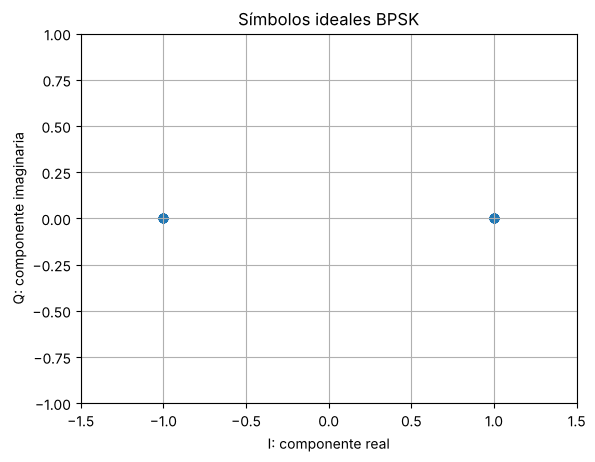

In [4]:
plt.scatter(symbols.real, symbols.imag)
plt.xlabel("I: componente real")
plt.ylabel("Q: componente imaginaria")
plt.title("Símbolos ideales BPSK")
plt.xlim(-1.5, 1.5)
plt.ylim(-1, 1)
plt.grid(True)
plt.show()

## Generalización a las 6 modulaciones

Todas las modulaciones del proyecto son una **tabla de $M$ puntos** de la que se sortean índices.

**PSK:** la misma idea de BPSK con $M$ fases separadas $2\pi/M$:
$$a_m = e^{j(2\pi m/M + \theta_0)}, \qquad m = 0,\dots,M-1$$
Con $M=2$ se recupera $\{+1,-1\}$. QPSK usa $\theta_0=\pi/4$.

**QAM:** cuadrícula con niveles impares $\{-(L-1),\dots,-1,+1,\dots,+(L-1)\}$ en I y en Q, con $L=\sqrt{M}$.

**16APSK:** 4 puntos en un anillo interior de radio $R_1$ y 12 en uno exterior de radio $R_2=\gamma R_1$ ($\gamma=2.57$, DVB-S2).

**Normalización:** se divide cada constelación entre $\sqrt{E_s}$, con $E_s=\overline{|a_m|^2}$, para que todas tengan energía media 1.
Sin normalizar, $E_s=10$ en 16-QAM y $E_s=42$ en 64-QAM; el mismo SNR significaría ruidos distintos para cada modulación.

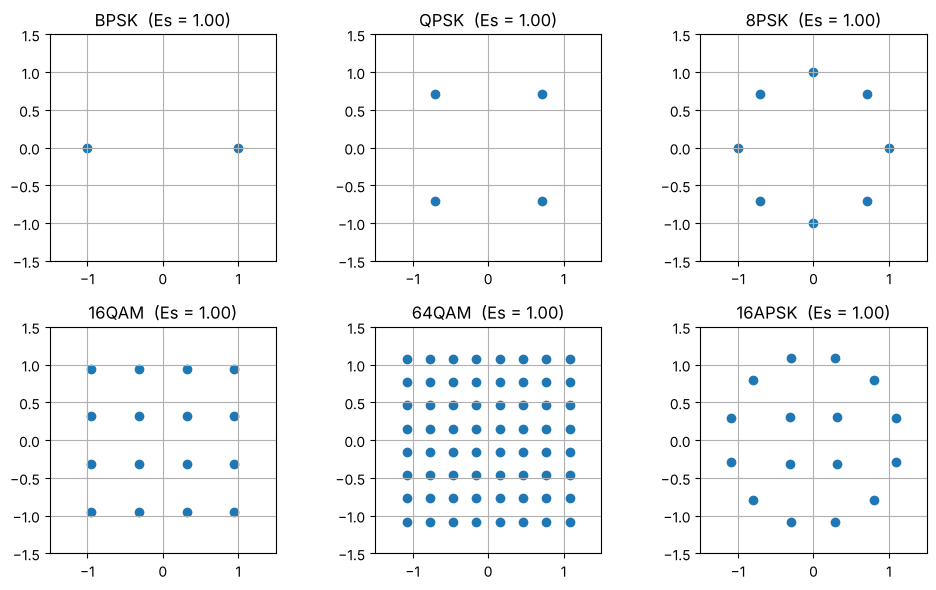

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(10, 6))
for ax, mod in zip(axes.ravel(), MODS):
    c = constellation(mod)
    ax.scatter(c.real, c.imag)
    ax.set_title("{}  (Es = {:.2f})".format(mod, np.mean(np.abs(c)**2)))
    ax.set_xlim(-1.5, 1.5)
    ax.set_ylim(-1.5, 1.5)
    ax.set_aspect("equal")
    ax.grid(True)
plt.tight_layout()
plt.savefig(ROOT / "figs" / "constelaciones.png")
plt.show()

## Paso 2 — Sobremuestreo y filtro de conformación RRC

Hasta aquí tenemos **números** $a_k$, uno por periodo de símbolo $T$. Para transmitirlos necesitamos una **señal continua**:
$$x(t) = \sum_k a_k\, p(t - kT)$$
donde $p(t)$ es el pulso que "dibuja" cada símbolo.

**¿Por qué no un pulso rectangular?** Un rectángulo de duración $T$ tiene espectro $\text{sinc}(fT)$, que decae lentamente y ocupa ancho de banda infinito: interfiere con los canales vecinos.

**Criterio de Nyquist (cero ISI):** queremos que, al muestrear en $t = kT$, cada muestra dependa solo de $a_k$. Eso exige $p(kT) = 0$ para todo $k \neq 0$. El **coseno alzado (RC)** cumple esto con un espectro limitado a
$$B = \frac{1+\beta}{2T}$$
donde el roll-off $\beta \in [0,1]$ intercambia ancho de banda por pulsos más cortos en el tiempo.

**¿Por qué raíz (RRC)?** El receptor óptimo frente a ruido blanco es el *filtro acoplado*: el mismo pulso, invertido en el tiempo. Si TX y RX usan cada uno $\sqrt{\text{RC}}$, la cadena completa es $\text{RRC} * \text{RRC} = \text{RC}$: se maximiza el SNR **y** se cumple Nyquist.

**En tiempo discreto:** con $sps = 8$ muestras por símbolo, se insertan 7 ceros entre símbolos (`upsample`) y se convoluciona con los taps del RRC (`np.convolve`). El filtro se trunca a `span = 10` símbolos (81 taps) y se normaliza a energía unitaria, $\sum h[n]^2 = 1$.

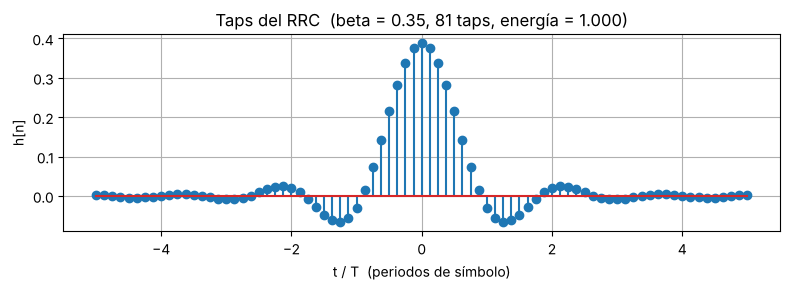

In [6]:
sps, beta, span = 8, 0.35, 10
h = rrc_taps(beta, sps, span)
n = np.arange(len(h)) - len(h) // 2

plt.figure(figsize=(8, 3))
plt.stem(n / sps, h)
plt.xlabel("t / T  (periodos de símbolo)")
plt.ylabel("h[n]")
plt.title("Taps del RRC  (beta = {}, {} taps, energía = {:.3f})".format(beta, len(h), np.sum(h**2)))
plt.grid(True)
plt.tight_layout()
plt.savefig(ROOT / "figs" / "rrc_taps.png")
plt.show()

A diferencia del RC, el RRC **no** pasa por cero en todos los enteros $t/T$: el cero de ISI solo aparece después del filtro acoplado. Por eso, en la gráfica siguiente, la señal pasa *cerca* de los símbolos escalados pero no exactamente por ellos: los vecinos todavía interfieren.

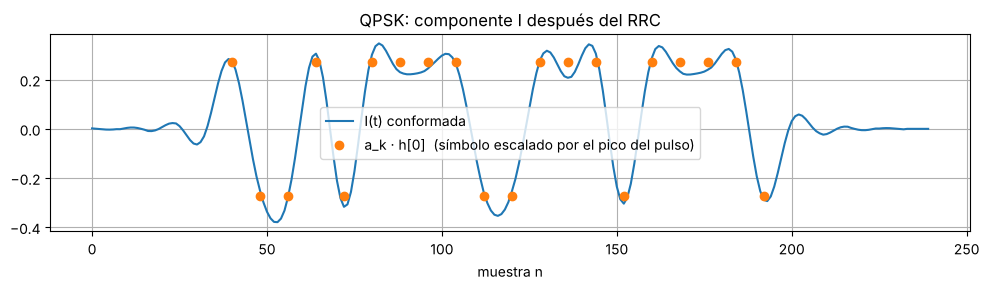

In [7]:
rng = np.random.default_rng(7)
s = random_symbols("QPSK", 20, rng)
x = pulse_shape(s, sps, beta, span)
delay = len(h) // 2                      # retardo de un RRC: (taps-1)/2 muestras

t = np.arange(len(x))
plt.figure(figsize=(10, 3))
plt.plot(t, x.real, label="I(t) conformada")
plt.plot(delay + sps * np.arange(len(s)), s.real * h.max(), "o", label="a_k · h[0]  (símbolo escalado por el pico del pulso)")
plt.xlabel("muestra n")
plt.title("QPSK: componente I después del RRC")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(ROOT / "figs" / "rrc_tiempo.png")
plt.show()

### Espectro

La densidad espectral se estima con el método de **Welch**: se parte la señal en tramos, se calcula la FFT de cada uno y se promedian los $|X(f)|^2$. Promediar reduce la varianza del estimado.

Con frecuencia normalizada a la tasa de muestreo $f_s$, la tasa de símbolos es $R_s = f_s/sps$, así que el borde teórico del espectro está en
$$f = \pm\frac{(1+\beta)}{2\,sps} = \pm\frac{1.35}{16} \approx \pm 0.084\, f_s$$

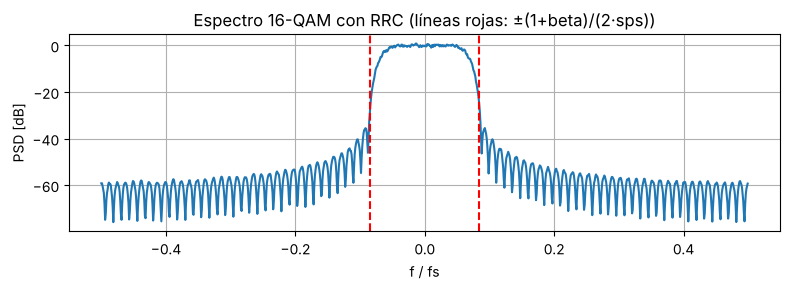

In [8]:
x_long = modulate("16QAM", 2**16, rng, sps, beta, span)
f, Pxx = welch(x_long, fs=1.0, nperseg=1024, detrend=False, return_onesided=False)
f, Pxx = np.fft.fftshift(f), np.fft.fftshift(Pxx)
edge = (1 + beta) / (2 * sps)

plt.figure(figsize=(8, 3))
plt.plot(f, 10 * np.log10(Pxx))
for e in (-edge, edge):
    plt.axvline(e, color="r", linestyle="--")
plt.xlabel("f / fs")
plt.ylabel("PSD [dB]")
plt.title("Espectro 16-QAM con RRC (líneas rojas: ±(1+beta)/(2·sps))")
plt.grid(True)
plt.tight_layout()
plt.savefig(ROOT / "figs" / "rrc_espectro.png")
plt.show()

### Verificación: filtro acoplado → cero ISI

Si todo está bien, al pasar la señal por un segundo RRC y muestrear cada $sps$ muestras (con el retardo total de los dos filtros) debemos recuperar los símbolos originales. El **diagrama de ojo** superpone tramos de 2 símbolos: en el instante óptimo el "ojo" se cierra en los niveles de la constelación.

Error máximo |r - s| = 0.0186  (ISI residual por truncar el filtro)


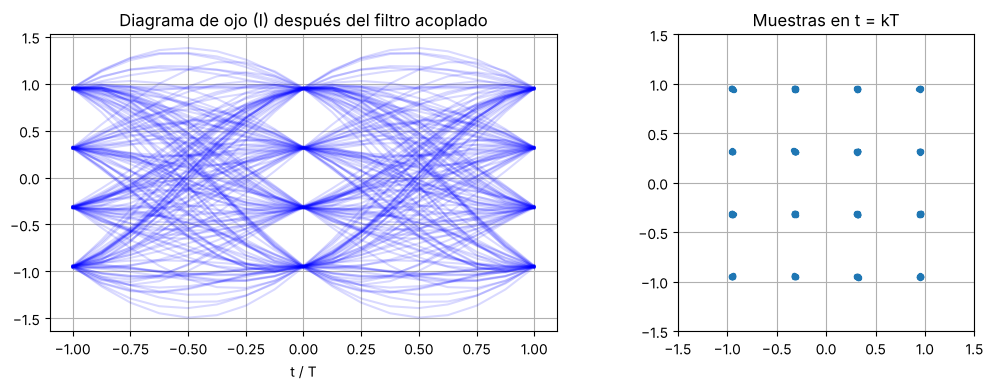

In [9]:
s = random_symbols("16QAM", 400, rng)
x = pulse_shape(s, sps, beta, span)
y = np.convolve(x, h)                    # filtro acoplado en el receptor
d = len(h) - 1                           # retardo total de los dos RRC
r = y[d::sps][:len(s)]                   # una muestra por símbolo
print("Error máximo |r - s| = {:.4f}  (ISI residual por truncar el filtro)".format(np.max(np.abs(r - s))))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
seg = 2 * sps
for k in range(20, 200):                 # salta los bordes
    i0 = d + k * sps - sps
    ax1.plot(np.arange(seg + 1) / sps - 1, y[i0:i0 + seg + 1].real, "b", alpha=0.15)
ax1.set_xlabel("t / T")
ax1.set_title("Diagrama de ojo (I) después del filtro acoplado")
ax1.grid(True)

ax2.scatter(r.real, r.imag, s=8)
ax2.set_aspect("equal")
ax2.set_xlim(-1.5, 1.5)
ax2.set_ylim(-1.5, 1.5)
ax2.set_title("Muestras en t = kT")
ax2.grid(True)
plt.tight_layout()
plt.savefig(ROOT / "figs" / "rrc_ojo.png")
plt.show()

## Paso 3 — Canal inalámbrico virtual

La señal limpia $x[n]$ se degrada como lo haría en el mundo real. El orden importa: primero lo que ocurre **en el aire** (multitrayecto), luego lo que ocurre **en el receptor** (osciladores, ruido térmico, ganancia).
$$y[n] = A\left[\Big(\sum_{l} h_l\, x[n-d_l]\Big)e^{j(2\pi \Delta f\, n + \phi)} + w[n]\right]$$

**1. Multitrayecto con fading Rayleigh.** La señal llega por varios caminos (directo, rebotes), cada uno con un retardo $d_l$ y una ganancia compleja $h_l$. Sumar copias retardadas es exactamente una **convolución** con $h = [h_0, 0, 0, h_1, \dots]$. Cada $h_l$ es a su vez la suma de muchísimos reflectores pequeños con fases aleatorias; por el teorema central del límite, esa suma tiende a una **gaussiana compleja**, y su magnitud $|h_l|$ sigue una distribución **Rayleigh**. Usamos 3 trayectos (retardos 0, 1 y 2 muestras; potencias 0, −10 y −20 dB) normalizados a $\sum E|h_l|^2 = 1$: en promedio la energía no cambia, pero cada realización puede caer en un *desvanecimiento profundo*. El canal se mantiene constante durante las 1024 muestras (*block fading*).

**2. CFO y fase.** Los osciladores del TX y del RX nunca están exactamente a la misma frecuencia. La diferencia $\Delta f$ (en ciclos por muestra) hace que la constelación **gire continuamente**; $\phi$ es la fase inicial desconocida.

**3. Error de temporización.** `modulate(..., random_timing=True)` desplaza el inicio entre 0 y 7 muestras: el receptor no sabe en qué muestra cae cada símbolo.

**4. AWGN.** Ruido térmico: gaussiano, complejo, blanco. Convenio del proyecto: **$N_0 = 1$** (varianza del ruido por muestra) y la señal se escala a $E_s = 10^{\text{SNR}/10}$, así que el SNR etiquetado es $E_s/N_0$.

**5. Ganancia $A$.** Representa la ganancia desconocida del receptor. Multiplica señal y ruido por igual: cambia la potencia pero **no** el SNR. El preprocesamiento (Bloque 3) deberá deshacerla normalizando.

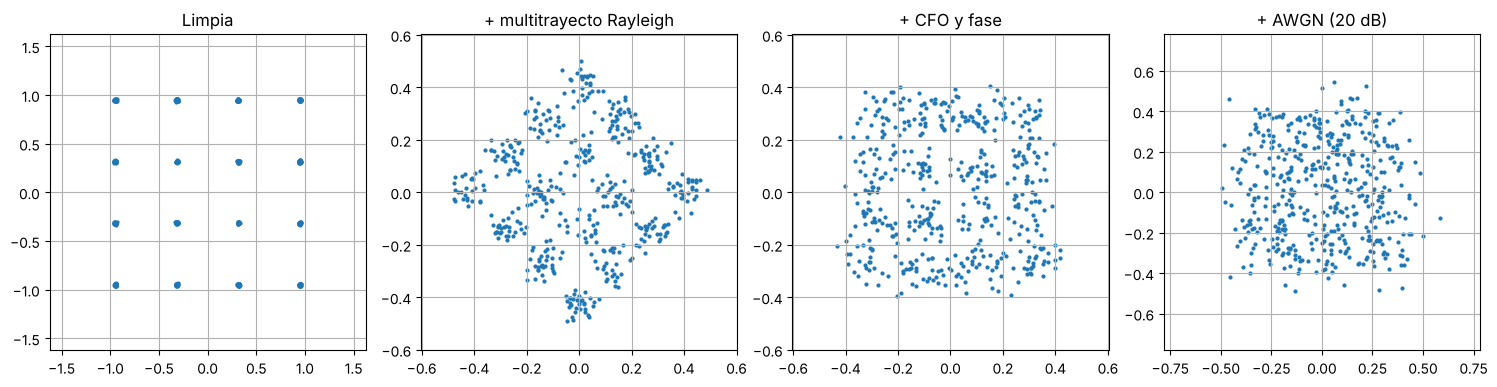

Taps del canal: [-0.416+0.248j  0.129-0.12j   0.085+0.104j]


In [10]:
rng = np.random.default_rng(11)
x = modulate("16QAM", 4096, rng, random_timing=False)
x_fad, h_ch = rayleigh_multipath(x, rng)
x_cfo = cfo_phase(x_fad, cfo=2.5e-5, phase=0.5)
x_awgn = x_cfo + awgn(len(x_cfo), rng) * np.sqrt(10 ** (-20 / 10))   # Es/N0 = 20 dB (Es = 1)

h = rrc_taps(0.35, 8, 10)
d = len(h) // 2                                   # retardo del filtro acoplado
etapas = [("Limpia", x), ("+ multitrayecto Rayleigh", x_fad),
          ("+ CFO y fase", x_cfo), ("+ AWGN (20 dB)", x_awgn)]

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, (nombre, sig) in zip(axes, etapas):
    r = np.convolve(sig, h)[d::8][20:-20]         # filtro acoplado + 1 muestra/símbolo
    lim = 1.2 * np.max(np.abs(r))
    ax.scatter(r.real, r.imag, s=4)
    ax.set_xlim(-lim, lim)
    ax.set_ylim(-lim, lim)
    ax.set_aspect("equal")
    ax.set_title(nombre)
    ax.grid(True)
plt.tight_layout()
plt.savefig(ROOT / "figs" / "canal_etapas.png")
plt.show()
print("Taps del canal:", np.round(h_ch, 3))

- **Multitrayecto:** el perfil importa muchísimo. Lo que decide la ISI es el *ensanchamiento de retardo* comparado con el periodo de símbolo $T = 8$ muestras. Con retardos de 0–2 muestras ($\le T/4$) los puntos se emborronan poco (EVM ≈ −25 dB); con 0–7 muestras (≈ $T$) y ecos de −4 dB, la constelación se destruye (EVM ≈ −7 dB) y ningún clasificador sin ecualizador la reconoce. El perfil fuerte se reserva para el **Experimento 6** (generalización).
  En la gráfica, la ganancia compleja dominante escala y rota la constelación; los trayectos retardados mezclan símbolos vecinos (ISI) y emborronan los puntos.
- **CFO:** el giro continuo convierte los puntos en **arcos**. La fase avanza $2\pi\,\Delta f\,N$: con $\Delta f = 2.5\times10^{-5}$ y $N = 4096$ son ≈ 37°, lo mismo que $\Delta f = 10^{-4}$ en una observación de 1024 muestras. Si el CFO es mucho mayor, los arcos se cierran en anillos y la constelación deja de ser visible: eso limita el rango de CFO del entrenamiento.
- **AWGN:** cada punto se vuelve una nube.

### Verificación del SNR

Sin fading, el SNR medido debe coincidir con el pedido. Con fading, el **instantáneo** varía en cada realización, pero su promedio lineal debe ser el pedido.

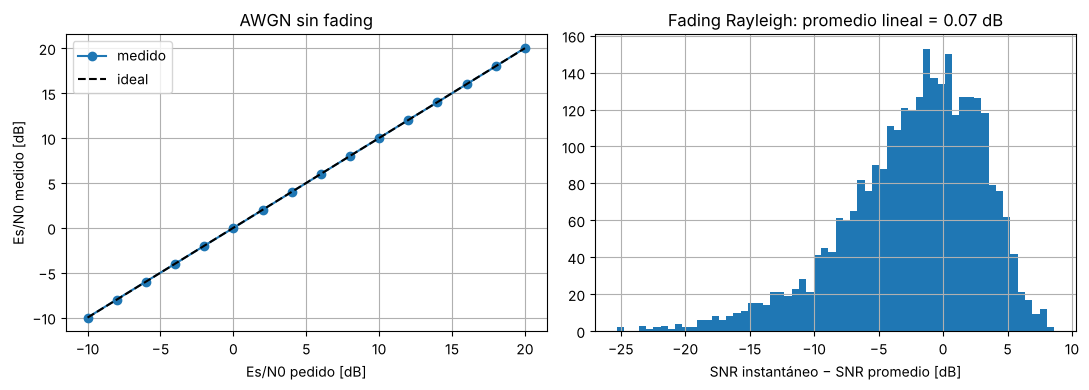

Realizaciones con desvanecimiento > 10 dB: 8.6 %


In [11]:
snrs = np.arange(-10, 22, 2)
medido = []
for snr in snrs:
    vals = []
    for _ in range(100):
        xs = modulate("QPSK", 1024, rng) * np.sqrt(10 ** (snr / 10))
        w = awgn(1024, rng)
        vals.append(10 * np.log10(8 * np.mean(np.abs(xs) ** 2) / np.mean(np.abs(w) ** 2)))
    medido.append(np.mean(vals))

delta = []
for _ in range(3000):
    _, meta = channel(modulate("QPSK", 1024, rng), rng, snr_db=10, fading=True)
    delta.append(meta["snr_inst_db"] - meta["snr_db"])
delta = np.array(delta)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(snrs, medido, "o-", label="medido")
ax1.plot(snrs, snrs, "k--", label="ideal")
ax1.set_xlabel("Es/N0 pedido [dB]")
ax1.set_ylabel("Es/N0 medido [dB]")
ax1.set_title("AWGN sin fading")
ax1.legend()
ax1.grid(True)

ax2.hist(delta, bins=60)
ax2.set_xlabel("SNR instantáneo − SNR promedio [dB]")
ax2.set_title("Fading Rayleigh: promedio lineal = {:.2f} dB".format(
    10 * np.log10(np.mean(10 ** (delta / 10)))))
ax2.grid(True)
plt.tight_layout()
plt.savefig(ROOT / "figs" / "canal_snr.png")
plt.show()
print("Realizaciones con desvanecimiento > 10 dB: {:.1f} %".format(100 * np.mean(delta < -10)))

La cola izquierda del histograma son los **desvanecimientos profundos**: una observación etiquetada como "10 dB" puede llegar realmente a 0 dB o menos. Por eso guardamos `snr_inst_db` en el dataset: el estimador de SNR (M2M4) mide el instantáneo, no el promedio.

### Señal vs. solo ruido

Adelanto del Bloque 2. Con 8 muestras por símbolo, la señal ocupa solo $\pm 0.084\, f_s$; fuera de esa banda solo hay ruido. Esa diferencia es la que aprovechará el detector.

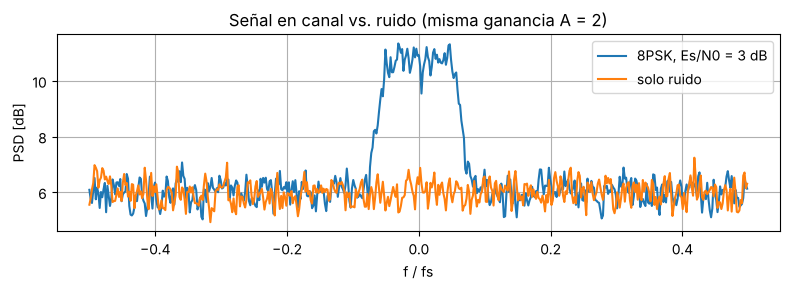

In [12]:
y_sig, _ = channel(modulate("8PSK", 2**15, rng), rng, snr_db=3, cfo=1e-4, phase=1.0, amp=2.0, fading=False)
y_noise = noise_only(2**15, rng, amp=2.0)

plt.figure(figsize=(8, 3))
for sig, lbl in [(y_sig, "8PSK, Es/N0 = 3 dB"), (y_noise, "solo ruido")]:
    f, P = welch(sig, fs=1.0, nperseg=512, detrend=False, return_onesided=False)
    plt.plot(np.fft.fftshift(f), 10 * np.log10(np.fft.fftshift(P)), label=lbl)
plt.xlabel("f / fs")
plt.ylabel("PSD [dB]")
plt.title("Señal en canal vs. ruido (misma ganancia A = 2)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(ROOT / "figs" / "canal_psd.png")
plt.show()